# 04 · T13 — Batch execution

**Deliverable (plan, section 6):** one command that runs every configuration and writes `results/`.

```bash
python scripts/run_batch.py --config configs/experiments/v1.yaml --dry-run   # grid and cost
python scripts/run_batch.py --config configs/experiments/v1.yaml --jobs 4    # run (resumable)
python scripts/run_batch.py --config configs/experiments/v1.yaml --only dataset=adult method=wachter
```

| plan requirement | implementation |
|---|---|
| declarative config | `configs/experiments/*.yaml`: `datasets × models × methods × seeds × budgets` |
| budget in queries | `CountingModel` (Wachter charges each gradient step) |
| curves, not a single point | each budget is an independent run **with the same search seed**; for MAP-Elites the run at budget *b* is an exact prefix of the larger run, i.e. the archive state at checkpoint *b* |
| resumable | a configuration with `runs/` and `summary/` written is skipped; atomic writes (`.tmp` + rename) |
| manifest per run | `results/<exp>/manifest.jsonl`: code hash, dataset md5, seed, budgets, time, parameters |
| `--dry-run` | grid, query ceiling and time estimated from the rates of existing manifests |

Outputs per configuration `<dataset>__<model>__<method>__seed<k>`: `runs/*.csv` (one row per counterfactual, Mary's
`results.py` format) and `summary/*.csv` (one row per instance × budget: validity, success, coverage, QD-score,
strategies, distance, L0, violations, diversity, redundancy, queries, time).

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
import numpy as np
import pandas as pd
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 220)
pd.set_option("display.max_colwidth", 80)

In [2]:
from cfqd.experiment import dry_run, estimate, load_experiment, load_summaries, run_grid, REGISTRY
print("registered methods:", sorted(REGISTRY))
for f in ["smoke", "v1", "full"]:
    print("=" * 100)
    print(dry_run(load_experiment(ROOT / "configs" / "experiments" / f"{f}.yaml")))

registered methods: ['dice_genetic', 'dice_random', 'face_knn', 'map_elites', 'wachter']


experiment: smoke
datasets=['german_credit'] models=['lr', 'rf', 'nn'] methods=['map_elites', 'dice_genetic', 'wachter', 'face_knn']
seeds=[0] budgets=[500, 2000] n_instances=3
configurations: 11 runnable, 1 skipped, 11 already done
explain() calls: 66
query ceiling: 82,500
estimated time (from manifest rates, 11 of 11 configs covered): 0.0 h sequential
skipped 1: method needs a gradient; RF has none


experiment: v1
datasets=['german_credit', 'adult'] models=['lr', 'rf', 'nn'] methods=['map_elites', 'dice_genetic', 'dice_random', 'wachter', 'face_knn']
seeds=[0, 1, 2] budgets=[500, 1000, 2000, 5000, 10000] n_instances=10
configurations: 84 runnable, 6 skipped, 0 already done
explain() calls: 4,200
query ceiling: 15,540,000
estimated time (from manifest rates, 66 of 84 configs covered): 2.2 h sequential
skipped 6: method needs a gradient; RF has none


experiment: full
datasets=['german_credit', 'adult', 'heloc', 'gmc', 'compas_guidotti', 'compas'] models=['lr', 'rf', 'nn'] methods=['map_elites', 'dice_genetic', 'dice_random', 'wachter', 'face_knn']
seeds=[0, 1, 2, 3, 4, 5, 6, 7, 8, 9] budgets=[500, 1000, 2000, 5000, 10000] n_instances=20
configurations: 700 runnable, 200 skipped, 30 already done
explain() calls: 70,000
query ceiling: 259,000,000
estimated time (from manifest rates, 380 of 700 configs covered): 18.8 h sequential
skipped 150: no actionable feature (strict actionability)
skipped 50: method needs a gradient; RF has none


## 1. The feasibility arithmetic (plan 6.1), with measured rates

Estimated time per (dataset, method) from the manifests already written (smoke, CARLA check, full run so far).
Combinations without a measurement show `NaN`. Treat it as an order of magnitude: DiCE dominates the cost per call;
MAP-Elites scales with the budget.

In [3]:
for f in ["v1", "full"]:
    est = estimate(load_experiment(ROOT / "configs" / "experiments" / f"{f}.yaml"))
    t = est.groupby(["dataset", "method"])["est_seconds"].sum(min_count=1).unstack() / 3600
    print(f"\n{f}: estimated sequential hours per dataset x method (NaN = not measured yet)")
    display(t.round(2))


v1: estimated sequential hours per dataset x method (NaN = not measured yet)


method,dice_genetic,dice_random,face_knn,map_elites,wachter
dataset,,,,,
adult,0.19,NaN,0.00,NaN,0.00
german_credit,1.38,0.04,0.05,0.49,0.01



full: estimated sequential hours per dataset x method (NaN = not measured yet)


method,dice_genetic,dice_random,face_knn,map_elites,wachter
dataset,,,,,
adult,1.27,NaN,0.01,NaN,0.02
compas_guidotti,2.88,NaN,0.03,NaN,0.07
german_credit,9.22,0.26,0.37,3.29,0.07
gmc,0.76,NaN,0.07,NaN,0.47
heloc,NaN,NaN,NaN,NaN,NaN


## 2. Budget curves — demo on German Credit

5 instances, seed 0, budgets 500 → 10,000. Written to `results/curve_demo/` (resumable).

In [4]:
exp_demo = load_experiment(ROOT / "configs" / "experiments" / "v1.yaml")
exp_demo.update(name="curve_demo", datasets=["german_credit"], seeds=[0], n_instances=5, out="results/curve_demo")
_ = run_grid(exp_demo, jobs=1)
s = load_summaries(exp_demo)
s.groupby(["model", "method", "budget"])[["success", "n_valid", "coverage", "n_strategies", "dist_min", "n_queries"]].mean().round(3)

14 configurations, 0 already done, 14 to run, 1 skipped


[1/14] german_credit__lr__map_elites__seed0: 59.1s


[2/14] german_credit__lr__dice_genetic__seed0: 113.94s


[3/14] german_credit__lr__dice_random__seed0: 7.24s


[4/14] german_credit__lr__wachter__seed0: 7.57s


[5/14] german_credit__lr__face_knn__seed0: 8.32s


... (6 outputs left out)

[12/14] german_credit__nn__dice_random__seed0: 6.65s


[13/14] german_credit__nn__wachter__seed0: 3.22s


[14/14] german_credit__nn__face_knn__seed0: 0.89s


success  n_valid  coverage  n_strategies  dist_min  n_queries
model method       budget                                                               
lr    dice_genetic 500         1.0     10.0     0.020           7.8     0.276      441.8
                   1000        1.0     10.0     0.020           7.4     0.273      757.4
                   2000        1.0     10.0     0.020           7.4     0.273      847.4
                   5000        1.0     10.0     0.020           7.4     0.273      847.4
                   10000       1.0     10.0     0.020           7.4     0.273      847.4
...                            ...      ...       ...           ...       ...        ...
rf    map_elites   500         1.0     53.6     0.134          31.0     0.042      500.0
                   1000        1.0     74.0     0.185          38.2     0.042     1000.0
                   2000        1.0     91.4     0.228          42.4     0.042     2000.0
                   5000        1.0    111.6     0.279          47.2     0.042     5000.0
                   10000       1.0    125.6     0.314          49.6     0.042    10000.0

[70 rows x 6 columns]

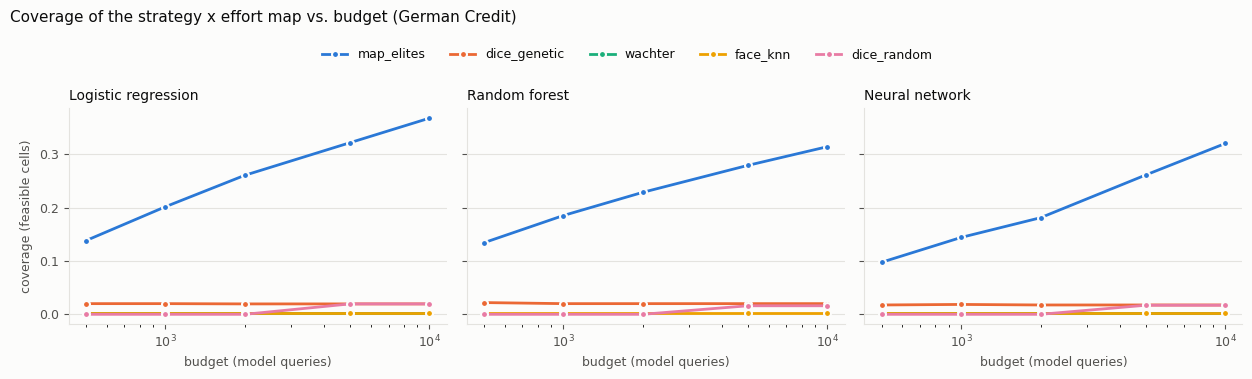

In [5]:
from cfqd.plots import budget_curves
fig = budget_curves(s, "coverage", "Coverage of the strategy x effort map vs. budget (German Credit)", "coverage (feasible cells)")

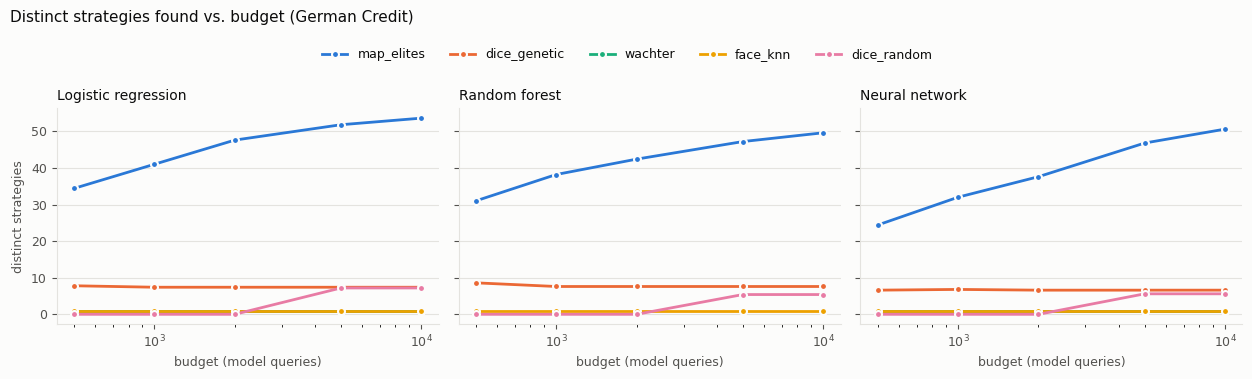

In [6]:
fig = budget_curves(s, "n_strategies", "Distinct strategies found vs. budget (German Credit)", "distinct strategies")

**What the curves show (and why the T13 design changed):** DiCE, Wachter and FACE converge with few queries and stay
**flat**: extra budget does not change what they return. MAP-Elites keeps filling the grid. A single budget
calibrated on DiCE would leave the archive of elites almost empty; one calibrated on MAP-Elites would give the
baselines queries they never use. Hence the curves (plan, pending item 4).

## 3. Resuming

Running again reprocesses nothing:

In [7]:
_ = run_grid(exp_demo, jobs=1)

14 configurations, 14 already done, 0 to run, 1 skipped


In [8]:
pd.read_json(ROOT / "results" / "curve_demo" / "manifest.jsonl", lines=True).tail(5)

,key,dataset,model,method,seed,budgets,n_instances,method_params,effort_edges,train_predictions,code,dataset_md5,generator_hash,seconds,python,torch,finished_at
9,german_credit__nn__map_elites__seed0,german_credit,nn,map_elites,0,"[500, 1000, 2000, 5000, 10000]",5,"{'batch_size': 50, 'n_init': 200}","[0.1, 0.25, 0.5, 1.0]",free,src:6f60dc36cd,f2ab24d5398cc5032615ac6e7a875d4b,NaN,67.62,3.9.0,2.8.0+cpu,2026-11-20 18:52:34+00:00
10,german_credit__nn__dice_genetic__seed0,german_credit,nn,dice_genetic,0,"[500, 1000, 2000, 5000, 10000]",5,{'total_cfs': 10},"[0.1, 0.25, 0.5, 1.0]",free,src:6f60dc36cd,f2ab24d5398cc5032615ac6e7a875d4b,NaN,200.42,3.9.0,2.8.0+cpu,2026-11-20 18:55:55+00:00
11,german_credit__nn__dice_random__seed0,german_credit,nn,dice_random,0,"[500, 1000, 2000, 5000, 10000]",5,{'total_cfs': 10},"[0.1, 0.25, 0.5, 1.0]",free,src:6f60dc36cd,f2ab24d5398cc5032615ac6e7a875d4b,NaN,6.65,3.9.0,2.8.0+cpu,2026-11-20 18:56:01+00:00
12,german_credit__nn__wachter__seed0,german_credit,nn,wachter,0,"[500, 1000, 2000, 5000, 10000]",5,{},"[0.1, 0.25, 0.5, 1.0]",free,src:6f60dc36cd,f2ab24d5398cc5032615ac6e7a875d4b,NaN,3.22,3.9.0,2.8.0+cpu,2026-11-20 18:56:05+00:00
13,german_credit__nn__face_knn__seed0,german_credit,nn,face_knn,0,"[500, 1000, 2000, 5000, 10000]",5,"{'n_neighbors': 50, 'frac': 0.4, 'max_pool': 2000}","[0.1, 0.25, 0.5, 1.0]",free,src:6f60dc36cd,f2ab24d5398cc5032615ac6e7a875d4b,NaN,0.89,3.9.0,2.8.0+cpu,2026-11-20 18:56:06+00:00
